In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense
from keras.models import Sequential

In [2]:
X,y = make_moons(n_samples=250,noise=0.2,random_state=42)

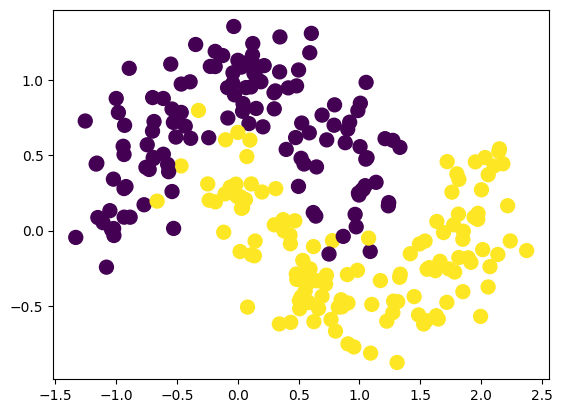

In [3]:
plt.scatter(X[:,0],X[:,1],c=y,s=100)
plt.show()

In [4]:
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [6]:
old_weights = model.get_weights()[0]

In [7]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [8]:
model.fit(X_train,y_train,epochs=100,batch_size=10)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.4900 - loss: 0.7118
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.6987
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4900 - loss: 0.6940
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.6919
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5500 - loss: 0.6899
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6900 - loss: 0.6891
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6800 - loss: 0.6877
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6800 - loss: 0.6865
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6850 - loss: 0.6852
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6600 - loss: 0.6838
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6100 - loss: 0.6821
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accura

In [9]:
new_weights = model.get_weights()[0]

In [10]:
model.optimizer.get_config()['learning_rate']

0.0010000000474974513

In [11]:
gradient = (old_weights - new_weights)/0.001
percent_change = abs(100*(old_weights-new_weights)/old_weights)
gradient

array([[   58.601734,   -11.50596 ,   290.25565 ,   -99.341805,
          339.62753 ,   -76.25341 ,  -417.1096  ,   -46.028313,
          -58.82704 ,   123.74308 ],
       [-1763.545   , -1661.6647  , -1570.3544  , -1613.0315  ,
        -1639.6213  ,  1595.7262  ,  1618.6974  ,  1894.3099  ,
         1738.7158  , -1582.5948  ]], dtype=float32)

In [12]:
percent_change

array([[1.1169470e+01, 1.6422462e+00, 2.8137341e+02, 1.4918599e+01,
        1.5367903e+02, 1.8857019e+01, 1.0820630e+02, 8.2876511e+00,
        1.2593076e+01, 3.7412868e+01],
       [2.1381873e+03, 3.3030399e+02, 1.8321326e+03, 3.9894931e+02,
        1.1820731e+03, 3.4659470e+02, 3.7037567e+02, 4.2353748e+02,
        7.1149396e+02, 1.6647692e+03]], dtype=float32)

In [13]:
loss_function = tf.keras.losses.BinaryCrossentropy()

with tf.GradientTape() as tape:

    predictions = model(X_train[:32], training=True)

    loss = loss_function(
        tf.cast(y_train[:32], tf.float32),
        predictions
    )

gradients = tape.gradient(
    loss,
    model.trainable_variables
)

for i, layer in enumerate(model.layers):

    kernel_gradient = gradients[2*i]

    gradient_norm = tf.norm(kernel_gradient)

    print(layer.name, gradient_norm.numpy())

dense 0.0032241703
dense_1 0.011394931
dense_2 0.00833555
dense_3 0.0280198


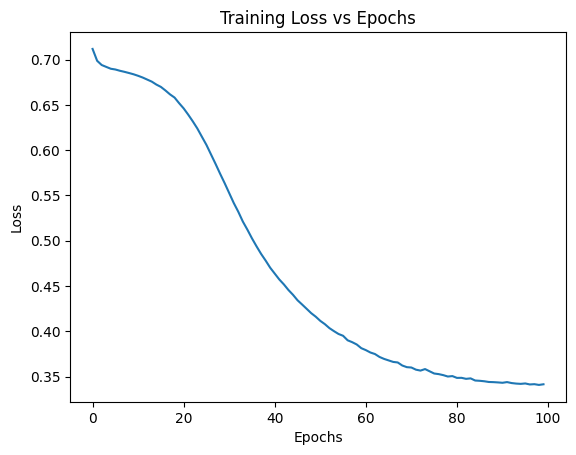

In [14]:
plt.plot(model.history.history['loss'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss vs Epochs')
plt.show()

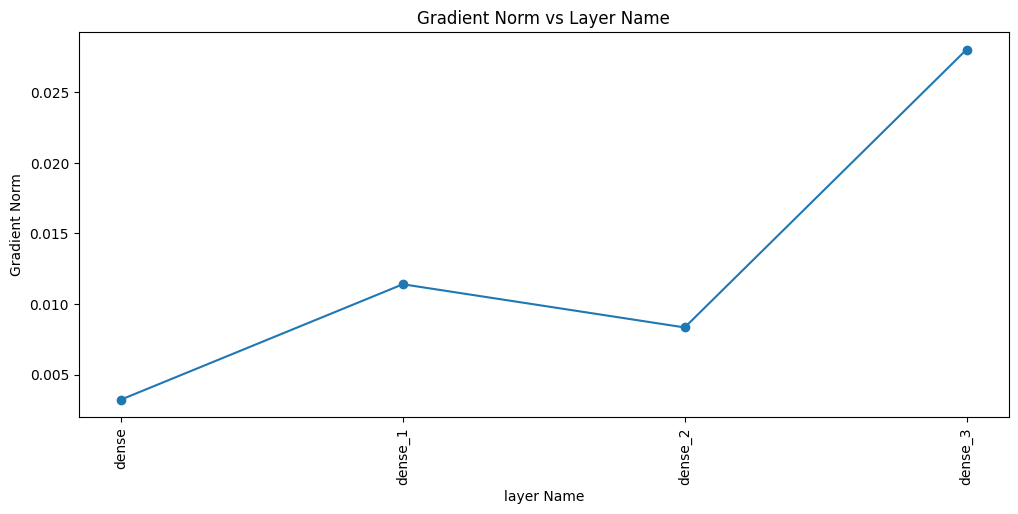

In [16]:
layers_names = []
gradient_values = []

for i,layer in enumerate(model.layers):
  kernel_gradient = gradients[2*i]
  gradient_norm = tf.norm(kernel_gradient)

  layers_names.append(layer.name)
  gradient_values.append(gradient_norm.numpy())
plt.figure(figsize=(12,5))
plt.plot(layers_names,gradient_values,marker='o')
plt.xlabel('layer Name')
plt.ylabel('Gradient Norm')
plt.title('Gradient Norm vs Layer Name')
plt.xticks(rotation=90)
plt.show()